In [1]:
import pandas as pd
import sqlite3

In [2]:
conn = sqlite3.connect('inventory.db')

In [7]:
for table in tables['name']:
    print('-'*50, f'{table}', '-'*50)
    print('Count of records:', pd.read_sql(f"select count(*) as count from {table}", conn)['count'].values[0])
    display(pd.read_sql(f"select* from {table} limit 5",conn))


-------------------------------------------------- audience_data --------------------------------------------------
Count of records: 500


,audience_id,campaign_id,audience_segment,country,device,impressions,clicks,conversions,revenue
0,A0001,C408,35-44,USA,Tablet,108160,788,161,12295.73
1,A0002,C297,25-34,Germany,Desktop,64337,3435,262,3867.10
2,A0003,C381,25-34,UK,Desktop,110012,3185,154,44384.23
3,A0004,C177,45-54,Australia,Mobile,79067,4224,197,33709.71
4,A0005,C035,25-34,India,Mobile,24310,3515,321,18414.56


-------------------------------------------------- campaigns --------------------------------------------------
Count of records: 500


,campaign_id,campaign_name,campaign_type,country,start_date,budget,status
0,C001,Brand Awareness,Retargeting,UK,2026-01-16,51536.64,Active
1,C002,Lead Generation,Retargeting,Australia,2026-03-19,27055.60,Active
2,C003,Retargeting,Promotional,Australia,2026-01-28,62156.06,Active
3,C004,Brand Awareness,Lead Generation,India,2026-03-24,94514.22,Active
4,C005,Holiday Sale,Retargeting,India,2026-03-31,36916.51,Active


-------------------------------------------------- campaign_performance --------------------------------------------------
Count of records: 500


,performance_id,campaign_id,date,device,channel,impressions,clicks,conversions,spend,revenue
0,P0001,C272,2026-03-24,Desktop,Connected TV,132049,6218,529,14070.88,42738.06
1,P0002,C174,2026-01-18,Mobile,Native,17682,6908,397,17985.34,15002.34
2,P0003,C312,2026-03-12,Mobile,Display,25977,230,73,12038.49,30115.22
3,P0004,C473,2026-02-13,Mobile,Native,71749,2872,37,13363.76,35512.06
4,P0005,C439,2026-02-12,Mobile,Connected TV,5145,5167,58,1258.44,28916.10


... (2 outputs left out)

-------------------------------------------------- geography --------------------------------------------------
Count of records: 500


,geo_id,campaign_id,country,region,impressions,clicks,conversions,spend,revenue
0,G0001,C497,UK,Central,46309,6973,59,12764.24,42191.08
1,G0002,C087,India,Central,92599,3092,436,5039.71,5316.79
2,G0003,C105,USA,South,41227,1647,449,5232.70,25063.04
3,G0004,C342,India,East,120796,2811,388,12027.10,24289.77
4,G0005,C294,USA,South,49933,5034,513,10048.84,37314.70


-------------------------------------------------- sales_conversions --------------------------------------------------
Count of records: 500


,conversion_id,campaign_id,date,country,device,conversion_type,conversions,conversion_value,customer_value
0,CV0001,C250,2026-02-11,UK,Tablet,Subscription,21,318.93,3618.52
1,CV0002,C470,2026-03-30,Germany,Desktop,Signup,21,631.45,4659.36
2,CV0003,C101,2026-01-24,USA,Mobile,Signup,61,1425.25,5436.06
3,CV0004,C321,2026-01-16,USA,Tablet,Subscription,15,1904.47,2509.30
4,CV0005,C439,2026-02-11,Australia,Desktop,Subscription,89,4051.11,4856.52


In [5]:
pd.read_sql("select count(*) from campaigns",conn)

,count(*)
0,500


In [9]:
pd.read_sql_query(
    """SELECT DISTINCT campaign_id 
       FROM campaign_performance
       LIMIT 20""",
    conn
)

,campaign_id
0,C272
1,C174
2,C312
3,C473
4,C439
5,C480
6,C223
7,C115
8,C267
9,C246


In [10]:
campaign_performance = pd.read_sql_query(
    """SELECT * 
       FROM campaign_performance 
       WHERE campaign_id = 'C223'""",
    conn
)

campaign_performance

,performance_id,campaign_id,date,device,channel,impressions,clicks,conversions,spend,revenue
0,P0007,C223,2026-03-17,Desktop,Native,84837,1158,143,13807.23,1897.08


In [11]:
campaign_performance = pd.read_sql_query(
    """SELECT * 
       FROM campaign_performance 
       WHERE campaign_id = 'C272'""",
    conn
)

campaign_performance

,performance_id,campaign_id,date,device,channel,impressions,clicks,conversions,spend,revenue
0,P0001,C272,2026-03-24,Desktop,Connected TV,132049,6218,529,14070.88,42738.06
1,P0121,C272,2026-03-26,Mobile,Native,132784,2794,468,12789.16,53220.54
2,P0201,C272,2026-01-22,Desktop,Video,136060,5627,220,19663.64,44304.24


In [14]:
audience_data = pd.read_sql_query(
    """SELECT *
       FROM audience_data
       WHERE campaign_id = 'C272'""",
    conn
)

audience_data

,audience_id,campaign_id,audience_segment,country,device,impressions,clicks,conversions,revenue
0,A0059,C272,25-34,USA,Mobile,7439,4253,224,2685.7


In [17]:
pd.read_sql_query(
    """PRAGMA table_info(campaign_performance)""",
    conn
)

,cid,name,type,notnull,dflt_value,pk
0,0,performance_id,TEXT,0,None,0
1,1,campaign_id,TEXT,0,None,0
2,2,date,TEXT,0,None,0
3,3,device,TEXT,0,None,0
4,4,channel,TEXT,0,None,0
5,5,impressions,BIGINT,0,None,0
6,6,clicks,BIGINT,0,None,0
7,7,conversions,BIGINT,0,None,0
8,8,spend,FLOAT,0,None,0
9,9,revenue,FLOAT,0,None,0


In [18]:
campaign_summary = pd.read_sql_query(
    """
    SELECT
        campaign_id,
        SUM(impressions) AS total_impressions,
        SUM(clicks) AS total_clicks,
        SUM(conversions) AS total_conversions,
        SUM(spend) AS total_spend,
        SUM(revenue) AS total_revenue
    FROM campaign_performance
    GROUP BY campaign_id
    """,
    conn
)

campaign_summary

,campaign_id,total_impressions,total_clicks,total_conversions,total_spend,total_revenue
0,C003,134339,2801,469,8613.29,41093.90
1,C004,78978,5146,60,16462.53,16701.17
2,C006,105325,3462,447,18186.36,26098.28
3,C007,70649,1307,383,9355.35,32823.67
4,C011,213412,4911,261,28309.06,91053.69
...,...,...,...,...,...,...
308,C496,194124,8090,550,25915.50,72738.34
309,C497,103019,304,68,10285.41,36230.99
310,C498,27537,764,38,13473.61,28368.19
311,C499,69341,224,573,5934.36,43637.19


In [19]:
campaign_performance.groupby('channel')[
    ['impressions', 'clicks', 'conversions', 'spend', 'revenue']
].sum()

,impressions,clicks,conversions,spend,revenue
channel,,,,,
Connected TV,132049,6218,529,14070.88,42738.06
Native,132784,2794,468,12789.16,53220.54
Video,136060,5627,220,19663.64,44304.24


In [27]:
campaign_performance.groupby('campaign_id')[
    ['revenue', 'spend', 'conversions']
].sum()

,revenue,spend,conversions
campaign_id,,,
C003,41093.90,8613.29,469
C004,16701.17,16462.53,60
C006,26098.28,18186.36,447
C007,32823.67,9355.35,383
C011,91053.69,28309.06,261
...,...,...,...
C496,72738.34,25915.50,550
C497,36230.99,10285.41,68
C498,28368.19,13473.61,38


In [24]:
sales_conversions = pd.read_sql_query(
    """SELECT * FROM sales_conversions""",
    conn
)

sales_conversions

,conversion_id,campaign_id,date,country,device,conversion_type,conversions,conversion_value,customer_value
0,CV0001,C250,2026-02-11,UK,Tablet,Subscription,21,318.93,3618.52
1,CV0002,C470,2026-03-30,Germany,Desktop,Signup,21,631.45,4659.36
2,CV0003,C101,2026-01-24,USA,Mobile,Signup,61,1425.25,5436.06
3,CV0004,C321,2026-01-16,USA,Tablet,Subscription,15,1904.47,2509.30
4,CV0005,C439,2026-02-11,Australia,Desktop,Subscription,89,4051.11,4856.52
...,...,...,...,...,...,...,...,...,...
495,CV0496,C189,2026-03-02,India,Tablet,Purchase,79,4493.57,9754.19
496,CV0497,C254,2026-02-11,USA,Tablet,Purchase,90,349.85,7298.16
497,CV0498,C215,2026-03-27,India,Tablet,Lead,18,1273.74,1360.04
498,CV0499,C220,2026-02-08,India,Mobile,Purchase,54,1079.49,9554.88


In [25]:
sales_conversion_summary = sales_conversions.groupby('campaign_id')[
    ['conversions', 'conversion_value', 'customer_value']
].sum()

sales_conversion_summary

,conversions,conversion_value,customer_value
campaign_id,,,
C001,70,4647.44,3283.74
C004,96,1442.59,256.13
C005,71,9691.60,13040.46
C006,62,1549.22,2496.18
C007,64,7741.84,12343.90
...,...,...,...
C495,51,257.41,2005.00
C496,11,4063.47,1688.35
C497,49,4579.47,6462.07


In [26]:
campaign_performance = pd.read_sql_query(
    """SELECT * FROM campaign_performance""",
    conn
)

campaign_performance

,performance_id,campaign_id,date,device,channel,impressions,clicks,conversions,spend,revenue
0,P0001,C272,2026-03-24,Desktop,Connected TV,132049,6218,529,14070.88,42738.06
1,P0002,C174,2026-01-18,Mobile,Native,17682,6908,397,17985.34,15002.34
2,P0003,C312,2026-03-12,Mobile,Display,25977,230,73,12038.49,30115.22
3,P0004,C473,2026-02-13,Mobile,Native,71749,2872,37,13363.76,35512.06
4,P0005,C439,2026-02-12,Mobile,Connected TV,5145,5167,58,1258.44,28916.10
...,...,...,...,...,...,...,...,...,...,...
495,P0496,C375,2026-03-31,Mobile,Native,148076,558,539,16937.48,10258.31
496,P0497,C364,2026-03-08,Mobile,Video,36497,3579,471,6364.81,11734.15
497,P0498,C257,2026-01-26,Mobile,Connected TV,30552,5757,72,1166.38,34278.29
498,P0499,C366,2026-01-10,Mobile,Video,26606,1735,391,13400.70,17502.08


In [28]:
campaign_performance.groupby('campaign_id')[
    ['revenue', 'spend', 'conversions']
].sum()

,revenue,spend,conversions
campaign_id,,,
C003,41093.90,8613.29,469
C004,16701.17,16462.53,60
C006,26098.28,18186.36,447
C007,32823.67,9355.35,383
C011,91053.69,28309.06,261
...,...,...,...
C496,72738.34,25915.50,550
C497,36230.99,10285.41,68
C498,28368.19,13473.61,38


In [29]:
performance_summary = campaign_performance.groupby(
    ['campaign_id', 'channel']
)[
    ['spend', 'revenue', 'conversions']
].sum()

performance_summary

,,spend,revenue,conversions
campaign_id,channel,,,
C003,Display,8613.29,41093.90,469
C004,Video,16462.53,16701.17,60
C006,Display,18186.36,26098.28,447
C007,Video,9355.35,32823.67,383
C011,Connected TV,13893.75,35961.58,150
...,...,...,...,...
C498,Native,13473.61,28368.19,38
C499,Connected TV,5934.36,43637.19,573
C500,Connected TV,14767.33,14694.07,522


In [2]:
import sqlite3

conn = sqlite3.connect("inventory.db")

In [3]:
import pandas as pd
import numpy as np

campaigns = pd.read_sql_query(
    "SELECT * FROM campaigns",
    conn
)

campaign_performance = pd.read_sql_query(
    "SELECT * FROM campaign_performance",
    conn
)

audience_data = pd.read_sql_query(
    "SELECT * FROM audience_data",
    conn
)

daily_metrics = pd.read_sql_query(
    "SELECT * FROM daily_metrics",
    conn
)

sales_conversions = pd.read_sql_query(
    "SELECT * FROM sales_conversions",
    conn
)

In [4]:
print("Campaigns:", campaigns.shape)
print("Campaign Performance:", campaign_performance.shape)
print("Audience Data:", audience_data.shape)
print("Daily Metrics:", daily_metrics.shape)
print("Sales Conversions:", sales_conversions.shape)

Campaigns: (500, 7)
Campaign Performance: (500, 10)
Audience Data: (500, 9)
Daily Metrics: (500, 8)
Sales Conversions: (500, 9)


In [5]:
print("Campaigns:", campaigns['campaign_id'].nunique())
print("Campaign Performance:", campaign_performance['campaign_id'].nunique())
print("Audience Data:", audience_data['campaign_id'].nunique())
print("Daily Metrics:", daily_metrics['campaign_id'].nunique())
print("Sales Conversions:", sales_conversions['campaign_id'].nunique())

Campaigns: 500
Campaign Performance: 313
Audience Data: 320
Daily Metrics: 308
Sales Conversions: 318


In [6]:
performance_summary = campaign_performance.groupby('campaign_id').agg(
    total_impressions=('impressions', 'sum'),
    total_clicks=('clicks', 'sum'),
    total_conversions=('conversions', 'sum'),
    total_spend=('spend', 'sum'),
    total_revenue=('revenue', 'sum')
).reset_index()

In [7]:
display(performance_summary.head())

,campaign_id,total_impressions,total_clicks,total_conversions,total_spend,total_revenue
0,C003,134339,2801,469,8613.29,41093.90
1,C004,78978,5146,60,16462.53,16701.17
2,C006,105325,3462,447,18186.36,26098.28
3,C007,70649,1307,383,9355.35,32823.67
4,C011,213412,4911,261,28309.06,91053.69


In [8]:
print("Rows:", len(performance_summary))
print("Unique campaigns:", performance_summary['campaign_id'].nunique())

Rows: 313
Unique campaigns: 313


In [9]:
audience_summary = audience_data.groupby('campaign_id').agg(
    audience_impressions=('impressions', 'sum'),
    audience_clicks=('clicks', 'sum'),
    audience_conversions=('conversions', 'sum'),
    audience_revenue=('revenue', 'sum')
).reset_index()

In [10]:
display(audience_summary.head())

,campaign_id,audience_impressions,audience_clicks,audience_conversions,audience_revenue
0,C002,30923,4577,199,40354.63
1,C003,102361,1914,76,21067.78
2,C004,216945,7787,247,7988.80
3,C006,80972,944,392,15707.92
4,C007,98477,3846,210,32033.74


In [11]:
print("Rows:", len(audience_summary))
print("Unique campaigns:", audience_summary['campaign_id'].nunique())

Rows: 320
Unique campaigns: 320


In [12]:
conversion_summary = sales_conversions.groupby('campaign_id').agg(
    sales_conversions=('conversions', 'sum'),
    total_conversion_value=('conversion_value', 'sum'),
    total_customer_value=('customer_value', 'sum')
).reset_index()

In [13]:
display(conversion_summary.head())

,campaign_id,sales_conversions,total_conversion_value,total_customer_value
0,C001,70,4647.44,3283.74
1,C004,96,1442.59,256.13
2,C005,71,9691.60,13040.46
3,C006,62,1549.22,2496.18
4,C007,64,7741.84,12343.90


In [14]:
print("Rows:", len(conversion_summary))
print("Unique campaigns:", conversion_summary['campaign_id'].nunique())

Rows: 318
Unique campaigns: 318


In [15]:
campaign_master = campaigns.merge(
    performance_summary,
    on='campaign_id',
    how='left'
)

In [16]:
campaign_master = campaign_master.merge(
    audience_summary,
    on='campaign_id',
    how='left'
)

In [17]:
campaign_master = campaign_master.merge(
    conversion_summary,
    on='campaign_id',
    how='left'
)

In [18]:
print("Campaigns before join:", len(campaigns))
print("Rows after join:", len(campaign_master))
print("Unique campaign IDs:", campaign_master['campaign_id'].nunique())

Campaigns before join: 500
Rows after join: 500
Unique campaign IDs: 500


In [19]:
assert len(campaign_master) == len(campaigns)
assert campaign_master['campaign_id'].nunique() == len(campaigns)

print("JOIN VALIDATION PASSED ✅")

JOIN VALIDATION PASSED ✅


In [20]:
print(campaign_master.shape)

(500, 19)


In [21]:
display(campaign_master.head())

,campaign_id,campaign_name,campaign_type,country,start_date,budget,status,total_impressions,total_clicks,total_conversions,total_spend,total_revenue,audience_impressions,audience_clicks,audience_conversions,audience_revenue,sales_conversions,total_conversion_value,total_customer_value
0,C001,Brand Awareness,Retargeting,UK,2026-01-16,51536.64,Active,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.0,4647.44,3283.74
1,C002,Lead Generation,Retargeting,Australia,2026-03-19,27055.60,Active,NaN,NaN,NaN,NaN,NaN,30923.0,4577.0,199.0,40354.63,NaN,NaN,NaN
2,C003,Retargeting,Promotional,Australia,2026-01-28,62156.06,Active,134339.0,2801.0,469.0,8613.29,41093.90,102361.0,1914.0,76.0,21067.78,NaN,NaN,NaN
3,C004,Brand Awareness,Lead Generation,India,2026-03-24,94514.22,Active,78978.0,5146.0,60.0,16462.53,16701.17,216945.0,7787.0,247.0,7988.80,96.0,1442.59,256.13
4,C005,Holiday Sale,Retargeting,India,2026-03-31,36916.51,Active,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,71.0,9691.60,13040.46


In [22]:
campaign_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   campaign_id             500 non-null    object 
 1   campaign_name           500 non-null    object 
 2   campaign_type           500 non-null    object 
 3   country                 500 non-null    object 
 4   start_date              500 non-null    object 
 5   budget                  500 non-null    float64
 6   status                  500 non-null    object 
 7   total_impressions       313 non-null    float64
 8   total_clicks            313 non-null    float64
 9   total_conversions       313 non-null    float64
 10  total_spend             313 non-null    float64
 11  total_revenue           313 non-null    float64
 12  audience_impressions    320 non-null    float64
 13  audience_clicks         320 non-null    float64
 14  audience_conversions    320 non-null    fl

In [23]:
campaign_master.isna().sum()

campaign_id                 0
campaign_name               0
campaign_type               0
country                     0
start_date                  0
budget                      0
status                      0
total_impressions         187
total_clicks              187
total_conversions         187
total_spend               187
total_revenue             187
audience_impressions      180
audience_clicks           180
audience_conversions      180
audience_revenue          180
sales_conversions         182
total_conversion_value    182
total_customer_value      182
dtype: int64

In [24]:
numeric_cols = [
    'total_impressions',
    'total_clicks',
    'total_conversions',
    'total_spend',
    'total_revenue',
    'audience_impressions',
    'audience_clicks',
    'audience_conversions',
    'audience_revenue',
    'sales_conversions',
    'total_conversion_value',
    'total_customer_value'
]

In [25]:
campaign_master[numeric_cols] = campaign_master[numeric_cols].fillna(0)

In [26]:
campaign_master[numeric_cols].isna().sum()

total_impressions         0
total_clicks              0
total_conversions         0
total_spend               0
total_revenue             0
audience_impressions      0
audience_clicks           0
audience_conversions      0
audience_revenue          0
sales_conversions         0
total_conversion_value    0
total_customer_value      0
dtype: int64

In [27]:
campaign_master['CTR'] = np.where(
    campaign_master['total_impressions'] > 0,
    campaign_master['total_clicks'] /
    campaign_master['total_impressions'] * 100,
    0
)

In [28]:
campaign_master['conversion_rate'] = np.where(
    campaign_master['total_clicks'] > 0,
    campaign_master['total_conversions'] /
    campaign_master['total_clicks'] * 100,
    0
)

In [29]:
campaign_master['ROAS'] = np.where(
    campaign_master['total_spend'] > 0,
    campaign_master['total_revenue'] /
    campaign_master['total_spend'],
    0
)

In [30]:
campaign_master['ROI'] = np.where(
    campaign_master['total_spend'] > 0,
    (
        (campaign_master['total_revenue'] -
         campaign_master['total_spend'])
        / campaign_master['total_spend']
    ) * 100,
    0
)

In [31]:
display(
    campaign_master[
        [
            'campaign_id',
            'campaign_name',
            'campaign_type',
            'country',
            'status',
            'total_spend',
            'total_revenue',
            'total_conversions',
            'CTR',
            'conversion_rate',
            'ROAS',
            'ROI'
        ]
    ].head(10)
)

,campaign_id,campaign_name,campaign_type,country,status,total_spend,total_revenue,total_conversions,CTR,conversion_rate,ROAS,ROI
0,C001,Brand Awareness,Retargeting,UK,Active,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.000000
1,C002,Lead Generation,Retargeting,Australia,Active,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.000000
2,C003,Retargeting,Promotional,Australia,Active,8613.29,41093.90,469.0,2.085024,16.744020,4.770988,377.098762
3,C004,Brand Awareness,Lead Generation,India,Active,16462.53,16701.17,60.0,6.515739,1.165954,1.014496,1.449595
4,C005,Holiday Sale,Retargeting,India,Active,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.000000
5,C006,Product Launch,Retargeting,Australia,Completed,18186.36,26098.28,447.0,3.286969,12.911612,1.435047,43.504693
6,C007,Product Launch,Promotional,Germany,Active,9355.35,32823.67,383.0,1.849991,29.303749,3.508545,250.854538
7,C008,Brand Awareness,Promotional,Australia,Active,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.000000
8,C009,Product Launch,Lead Generation,India,Active,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.000000
9,C010,Brand Awareness,Retargeting,USA,Completed,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.000000


In [32]:
top_revenue_campaigns = campaign_master.sort_values(
    'total_revenue',
    ascending=False
)

display(
    top_revenue_campaigns[
        [
            'campaign_id',
            'campaign_name',
            'campaign_type',
            'country',
            'total_spend',
            'total_revenue',
            'total_conversions',
            'ROAS',
            'ROI'
        ]
    ].head(10)
)

,campaign_id,campaign_name,campaign_type,country,total_spend,total_revenue,total_conversions,ROAS,ROI
56,C057,Product Launch,Awareness,India,53701.60,232239.40,1470.0,4.324627,332.462720
139,C140,Retargeting,Retargeting,Australia,80659.03,203985.67,1253.0,2.528987,152.898739
41,C042,Product Launch,Promotional,UK,22236.47,155793.41,1485.0,7.006211,600.621142
285,C286,Holiday Sale,Retargeting,USA,35522.66,141080.25,1402.0,3.971556,297.155647
153,C154,Lead Generation,Awareness,India,47523.24,140794.12,1333.0,2.962637,196.263723
271,C272,Lead Generation,Awareness,Germany,46523.68,140262.84,1217.0,3.014870,201.486985
14,C015,Retargeting,Lead Generation,Germany,38817.85,137976.73,1394.0,3.554466,255.446605
315,C316,Product Launch,Lead Generation,India,29935.85,128151.80,1034.0,4.280881,328.088062
171,C172,Holiday Sale,Retargeting,Germany,36304.76,126985.85,742.0,3.497774,249.777412
360,C361,Lead Generation,Acquisition,Australia,49148.20,126224.61,1142.0,2.568245,156.824482


In [33]:
top_roas_campaigns = campaign_master.sort_values(
    'ROAS',
    ascending=False
)

display(
    top_roas_campaigns[
        [
            'campaign_id',
            'campaign_name',
            'campaign_type',
            'country',
            'total_spend',
            'total_revenue',
            'ROAS',
            'ROI'
        ]
    ].head(10)
)

,campaign_id,campaign_name,campaign_type,country,total_spend,total_revenue,ROAS,ROI
205,C206,Holiday Sale,Lead Generation,Australia,551.47,59170.43,107.295828,10629.582752
32,C033,Retargeting,Retargeting,USA,617.74,56008.44,90.666688,8966.668825
108,C109,Retargeting,Retargeting,India,524.81,25348.84,48.300985,4730.098512
73,C074,Lead Generation,Acquisition,Germany,1262.84,52878.29,41.872518,4087.251750
69,C070,Lead Generation,Awareness,Germany,1392.22,44153.31,31.714320,3071.431958
464,C465,Brand Awareness,Retargeting,Germany,1650.28,51915.41,31.458546,3045.854643
225,C226,Product Launch,Awareness,India,4025.24,110171.55,27.370182,2637.018165
260,C261,Product Launch,Acquisition,Germany,2221.55,58458.98,26.314501,2531.450114
228,C229,Lead Generation,Promotional,UK,1935.07,44578.39,23.037094,2203.709427
172,C173,Brand Awareness,Promotional,UK,1684.52,38548.56,22.884003,2188.400256


In [34]:
print(
    "Performance campaigns missing from master:",
    ~performance_summary['campaign_id'].isin(
        campaigns['campaign_id']
    ).sum()
)

Performance campaigns missing from master: -314


In [35]:
print(
    "Performance IDs missing from campaigns:",
    performance_summary.loc[
        ~performance_summary['campaign_id'].isin(
            campaigns['campaign_id']
        )
    ].shape[0]
)

print(
    "Audience IDs missing from campaigns:",
    audience_summary.loc[
        ~audience_summary['campaign_id'].isin(
            campaigns['campaign_id']
        )
    ].shape[0]
)

print(
    "Conversion IDs missing from campaigns:",
    conversion_summary.loc[
        ~conversion_summary['campaign_id'].isin(
            campaigns['campaign_id']
        )
    ].shape[0]
)

Performance IDs missing from campaigns: 0
Audience IDs missing from campaigns: 0
Conversion IDs missing from campaigns: 0


In [36]:
daily_trend = daily_metrics.groupby('date').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    conversions=('conversions', 'sum'),
    spend=('spend', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

In [37]:
daily_trend['CTR'] = np.where(
    daily_trend['impressions'] > 0,
    daily_trend['clicks'] / daily_trend['impressions'] * 100,
    0
)

daily_trend['conversion_rate'] = np.where(
    daily_trend['clicks'] > 0,
    daily_trend['conversions'] / daily_trend['clicks'] * 100,
    0
)

daily_trend['ROAS'] = np.where(
    daily_trend['spend'] > 0,
    daily_trend['revenue'] / daily_trend['spend'],
    0
)

In [38]:
print(campaign_master.shape)
print(campaign_master['campaign_id'].nunique())
display(campaign_master.head())

(500, 23)
500


,campaign_id,campaign_name,campaign_type,country,start_date,budget,status,total_impressions,total_clicks,total_conversions,...,audience_clicks,audience_conversions,audience_revenue,sales_conversions,total_conversion_value,total_customer_value,CTR,conversion_rate,ROAS,ROI
0,C001,Brand Awareness,Retargeting,UK,2026-01-16,51536.64,Active,0.0,0.0,0.0,...,0.0,0.0,0.00,70.0,4647.44,3283.74,0.000000,0.000000,0.000000,0.000000
1,C002,Lead Generation,Retargeting,Australia,2026-03-19,27055.60,Active,0.0,0.0,0.0,...,4577.0,199.0,40354.63,0.0,0.00,0.00,0.000000,0.000000,0.000000,0.000000
2,C003,Retargeting,Promotional,Australia,2026-01-28,62156.06,Active,134339.0,2801.0,469.0,...,1914.0,76.0,21067.78,0.0,0.00,0.00,2.085024,16.744020,4.770988,377.098762
3,C004,Brand Awareness,Lead Generation,India,2026-03-24,94514.22,Active,78978.0,5146.0,60.0,...,7787.0,247.0,7988.80,96.0,1442.59,256.13,6.515739,1.165954,1.014496,1.449595
4,C005,Holiday Sale,Retargeting,India,2026-03-31,36916.51,Active,0.0,0.0,0.0,...,0.0,0.0,0.00,71.0,9691.60,13040.46,0.000000,0.000000,0.000000,0.000000


In [39]:
campaign_master[
    [
        'total_impressions',
        'total_clicks',
        'total_conversions',
        'total_spend',
        'total_revenue',
        'CTR',
        'conversion_rate',
        'ROAS',
        'ROI'
    ]
].describe()

,total_impressions,total_clicks,total_conversions,total_spend,total_revenue,CTR,conversion_rate,ROAS,ROI
count,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,78261.896000,3508.93400,306.212000,10252.485900,30507.401660,4.972455,8.796821,3.266364,264.036413
std,90026.882258,3933.46761,350.840741,12027.253512,36068.981567,10.766242,20.293210,7.951007,781.056802
min,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-86.260242
25%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,57135.500000,2548.00000,194.000000,6873.580000,21233.490000,2.352297,4.659731,1.433798,43.379845
75%,135627.250000,5996.25000,508.500000,16966.570000,50699.352500,5.264752,10.532133,3.469047,246.904745
max,425511.000000,18312.00000,1548.000000,80659.030000,232239.400000,118.357574,255.803571,107.295828,10629.582752


In [40]:
campaign_type_analysis = campaign_master.groupby('campaign_type').agg(
    campaigns=('campaign_id', 'count'),
    impressions=('total_impressions', 'sum'),
    clicks=('total_clicks', 'sum'),
    conversions=('total_conversions', 'sum'),
    spend=('total_spend', 'sum'),
    revenue=('total_revenue', 'sum')
).reset_index()

campaign_type_analysis['CTR'] = np.where(
    campaign_type_analysis['impressions'] > 0,
    campaign_type_analysis['clicks'] /
    campaign_type_analysis['impressions'] * 100,
    0
)

campaign_type_analysis['conversion_rate'] = np.where(
    campaign_type_analysis['clicks'] > 0,
    campaign_type_analysis['conversions'] /
    campaign_type_analysis['clicks'] * 100,
    0
)

campaign_type_analysis['ROAS'] = np.where(
    campaign_type_analysis['spend'] > 0,
    campaign_type_analysis['revenue'] /
    campaign_type_analysis['spend'],
    0
)

campaign_type_analysis

,campaign_type,campaigns,impressions,clicks,conversions,spend,revenue,CTR,conversion_rate,ROAS
0,Acquisition,98,7582568.0,350646.0,30462.0,908289.04,3072548.26,4.624370,8.687394,3.382787
1,Awareness,103,9153250.0,369716.0,31401.0,1061886.54,3204914.06,4.039177,8.493276,3.018132
2,Lead Generation,93,7015707.0,304160.0,29479.0,975625.04,2725154.14,4.335415,9.691938,2.793239
3,Promotional,106,7436104.0,371939.0,31226.0,1001364.01,3222062.58,5.001799,8.395463,3.217674
4,Retargeting,100,7943319.0,358006.0,30538.0,1179078.32,3029021.79,4.507008,8.530025,2.568974


In [41]:
country_analysis = campaign_master.groupby('country').agg(
    campaigns=('campaign_id', 'count'),
    impressions=('total_impressions', 'sum'),
    clicks=('total_clicks', 'sum'),
    conversions=('total_conversions', 'sum'),
    spend=('total_spend', 'sum'),
    revenue=('total_revenue', 'sum')
).reset_index()

country_analysis['CTR'] = np.where(
    country_analysis['impressions'] > 0,
    country_analysis['clicks'] /
    country_analysis['impressions'] * 100,
    0
)

country_analysis['conversion_rate'] = np.where(
    country_analysis['clicks'] > 0,
    country_analysis['conversions'] /
    country_analysis['clicks'] * 100,
    0
)

country_analysis['ROAS'] = np.where(
    country_analysis['spend'] > 0,
    country_analysis['revenue'] /
    country_analysis['spend'],
    0
)

country_analysis

,country,campaigns,impressions,clicks,conversions,spend,revenue,CTR,conversion_rate,ROAS
0,Australia,88,7612461.0,330484.0,27535.0,986382.68,2677613.63,4.341356,8.331720,2.714579
1,Germany,102,7707708.0,335367.0,30858.0,983949.14,2830519.83,4.351060,9.201263,2.876693
2,India,108,7938979.0,365272.0,32917.0,1161928.34,3385522.77,4.600995,9.011641,2.913710
3,UK,101,8599795.0,388499.0,31092.0,1034136.21,3257351.81,4.517538,8.003109,3.149829
4,USA,101,7272005.0,334845.0,30704.0,959846.58,3102692.79,4.604576,9.169616,3.232488


In [42]:
channel_analysis = campaign_performance.groupby('channel').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    conversions=('conversions', 'sum'),
    spend=('spend', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

channel_analysis['CTR'] = np.where(
    channel_analysis['impressions'] > 0,
    channel_analysis['clicks'] /
    channel_analysis['impressions'] * 100,
    0
)

channel_analysis['conversion_rate'] = np.where(
    channel_analysis['clicks'] > 0,
    channel_analysis['conversions'] /
    channel_analysis['clicks'] * 100,
    0
)

channel_analysis['ROAS'] = np.where(
    channel_analysis['spend'] > 0,
    channel_analysis['revenue'] /
    channel_analysis['spend'],
    0
)

channel_analysis

,channel,impressions,clicks,conversions,spend,revenue,CTR,conversion_rate,ROAS
0,Connected TV,8508782,389008,36259,1158751.68,3279503.53,4.571841,9.320888,2.830204
1,Display,10259212,477597,40000,1380700.25,4200081.62,4.655299,8.375262,3.041994
2,Native,9597712,365347,31335,1313322.49,3727093.81,3.806605,8.576778,2.837912
3,Video,10765242,522515,45512,1273468.53,4047021.87,4.853723,8.710181,3.177952


In [43]:
device_analysis = campaign_performance.groupby('device').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    conversions=('conversions', 'sum'),
    spend=('spend', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

device_analysis['CTR'] = np.where(
    device_analysis['impressions'] > 0,
    device_analysis['clicks'] /
    device_analysis['impressions'] * 100,
    0
)

device_analysis['conversion_rate'] = np.where(
    device_analysis['clicks'] > 0,
    device_analysis['conversions'] /
    device_analysis['clicks'] * 100,
    0
)

device_analysis['ROAS'] = np.where(
    device_analysis['spend'] > 0,
    device_analysis['revenue'] /
    device_analysis['spend'],
    0
)

device_analysis

,device,impressions,clicks,conversions,spend,revenue,CTR,conversion_rate,ROAS
0,Desktop,13174842,589854,47822,1688608.64,4830131.29,4.477124,8.107430,2.860421
1,Mobile,21368705,958638,90088,2811929.07,8754554.47,4.486177,9.397499,3.113362
2,Tablet,4587401,205975,15196,625705.24,1669015.07,4.490015,7.377594,2.667414


In [44]:
audience_analysis = audience_data.groupby('audience_segment').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    conversions=('conversions', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

audience_analysis['CTR'] = np.where(
    audience_analysis['impressions'] > 0,
    audience_analysis['clicks'] /
    audience_analysis['impressions'] * 100,
    0
)

audience_analysis['conversion_rate'] = np.where(
    audience_analysis['clicks'] > 0,
    audience_analysis['conversions'] /
    audience_analysis['clicks'] * 100,
    0
)

audience_analysis

,audience_segment,impressions,clicks,conversions,revenue,CTR,conversion_rate
0,18-24,5700475,230026,22390,2528305.79,4.035208,9.733682
1,25-34,4628722,220943,19179,2178660.19,4.773305,8.680519
2,35-44,7229564,255833,24784,2462471.46,3.538706,9.687570
3,45-54,5503312,249621,22477,2310168.30,4.535832,9.004451
4,55+,7317068,274918,25773,2973192.52,3.757215,9.374795


In [45]:
top_campaigns = campaign_master.sort_values(
    'total_revenue',
    ascending=False
)[
    [
        'campaign_id',
        'campaign_name',
        'campaign_type',
        'country',
        'total_spend',
        'total_revenue',
        'total_conversions',
        'ROAS',
        'ROI'
    ]
]

top_campaigns.head(10)

,campaign_id,campaign_name,campaign_type,country,total_spend,total_revenue,total_conversions,ROAS,ROI
56,C057,Product Launch,Awareness,India,53701.60,232239.40,1470.0,4.324627,332.462720
139,C140,Retargeting,Retargeting,Australia,80659.03,203985.67,1253.0,2.528987,152.898739
41,C042,Product Launch,Promotional,UK,22236.47,155793.41,1485.0,7.006211,600.621142
285,C286,Holiday Sale,Retargeting,USA,35522.66,141080.25,1402.0,3.971556,297.155647
153,C154,Lead Generation,Awareness,India,47523.24,140794.12,1333.0,2.962637,196.263723
271,C272,Lead Generation,Awareness,Germany,46523.68,140262.84,1217.0,3.014870,201.486985
14,C015,Retargeting,Lead Generation,Germany,38817.85,137976.73,1394.0,3.554466,255.446605
315,C316,Product Launch,Lead Generation,India,29935.85,128151.80,1034.0,4.280881,328.088062
171,C172,Holiday Sale,Retargeting,Germany,36304.76,126985.85,742.0,3.497774,249.777412
360,C361,Lead Generation,Acquisition,Australia,49148.20,126224.61,1142.0,2.568245,156.824482


In [46]:
top_roas_campaigns = campaign_master.sort_values(
    'ROAS',
    ascending=False
)[
    [
        'campaign_id',
        'campaign_name',
        'campaign_type',
        'country',
        'total_spend',
        'total_revenue',
        'total_conversions',
        'ROAS',
        'ROI'
    ]
]

top_roas_campaigns.head(10)

,campaign_id,campaign_name,campaign_type,country,total_spend,total_revenue,total_conversions,ROAS,ROI
205,C206,Holiday Sale,Lead Generation,Australia,551.47,59170.43,456.0,107.295828,10629.582752
32,C033,Retargeting,Retargeting,USA,617.74,56008.44,98.0,90.666688,8966.668825
108,C109,Retargeting,Retargeting,India,524.81,25348.84,537.0,48.300985,4730.098512
73,C074,Lead Generation,Acquisition,Germany,1262.84,52878.29,158.0,41.872518,4087.251750
69,C070,Lead Generation,Awareness,Germany,1392.22,44153.31,537.0,31.714320,3071.431958
464,C465,Brand Awareness,Retargeting,Germany,1650.28,51915.41,558.0,31.458546,3045.854643
225,C226,Product Launch,Awareness,India,4025.24,110171.55,868.0,27.370182,2637.018165
260,C261,Product Launch,Acquisition,Germany,2221.55,58458.98,67.0,26.314501,2531.450114
228,C229,Lead Generation,Promotional,UK,1935.07,44578.39,63.0,23.037094,2203.709427
172,C173,Brand Awareness,Promotional,UK,1684.52,38548.56,94.0,22.884003,2188.400256


In [47]:
daily_trend = daily_metrics.groupby('date').agg(
    impressions=('impressions', 'sum'),
    clicks=('clicks', 'sum'),
    conversions=('conversions', 'sum'),
    spend=('spend', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

daily_trend['CTR'] = np.where(
    daily_trend['impressions'] > 0,
    daily_trend['clicks'] /
    daily_trend['impressions'] * 100,
    0
)

daily_trend['conversion_rate'] = np.where(
    daily_trend['clicks'] > 0,
    daily_trend['conversions'] /
    daily_trend['clicks'] * 100,
    0
)

daily_trend['ROAS'] = np.where(
    daily_trend['spend'] > 0,
    daily_trend['revenue'] /
    daily_trend['spend'],
    0
)

daily_trend

,date,impressions,clicks,conversions,spend,revenue,CTR,conversion_rate,ROAS
0,2026-01-01,719915,21640,2296,86582.46,234766.60,3.005910,10.609982,2.711480
1,2026-01-02,196261,19234,1691,60700.95,164344.09,9.800215,8.791723,2.707439
2,2026-01-03,321059,17899,1437,21906.02,96597.43,5.574988,8.028381,4.409629
3,2026-01-04,523968,19495,1986,52617.35,196223.27,3.720647,10.187227,3.729250
4,2026-01-05,778434,37389,2337,81187.93,164131.69,4.803105,6.250501,2.021627
...,...,...,...,...,...,...,...,...,...
84,2026-03-27,394252,30198,1785,46716.54,239400.06,7.659568,5.910987,5.124525
85,2026-03-28,303418,19823,499,38136.93,103142.89,6.533231,2.517278,2.704541
86,2026-03-29,432487,22418,1283,78451.18,98464.31,5.183508,5.723080,1.255103
87,2026-03-30,657709,33825,3061,69985.63,327429.59,5.142852,9.049520,4.678526


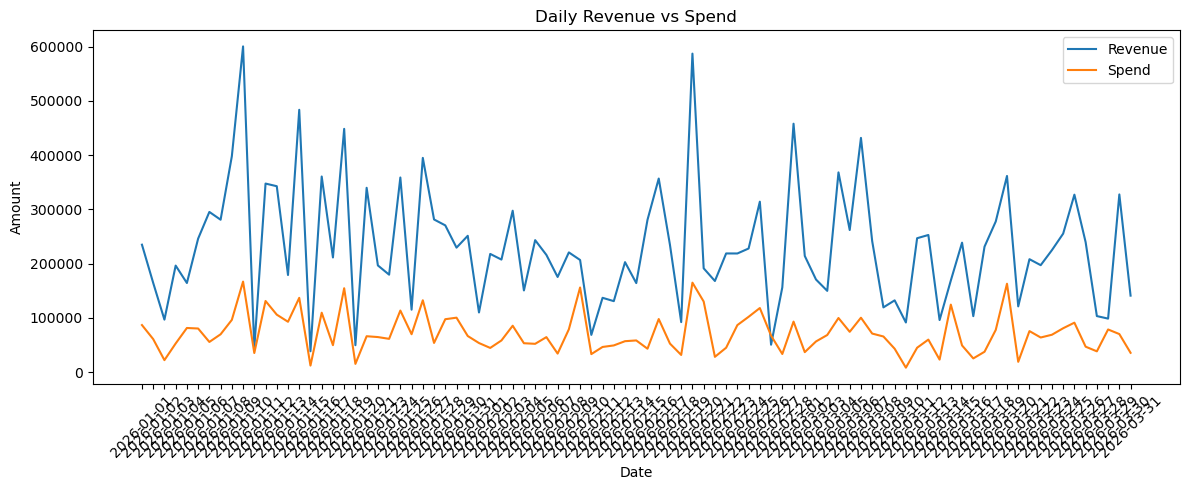

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    daily_trend['date'],
    daily_trend['revenue'],
    label='Revenue'
)

plt.plot(
    daily_trend['date'],
    daily_trend['spend'],
    label='Spend'
)

plt.title('Daily Revenue vs Spend')
plt.xlabel('Date')
plt.ylabel('Amount')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

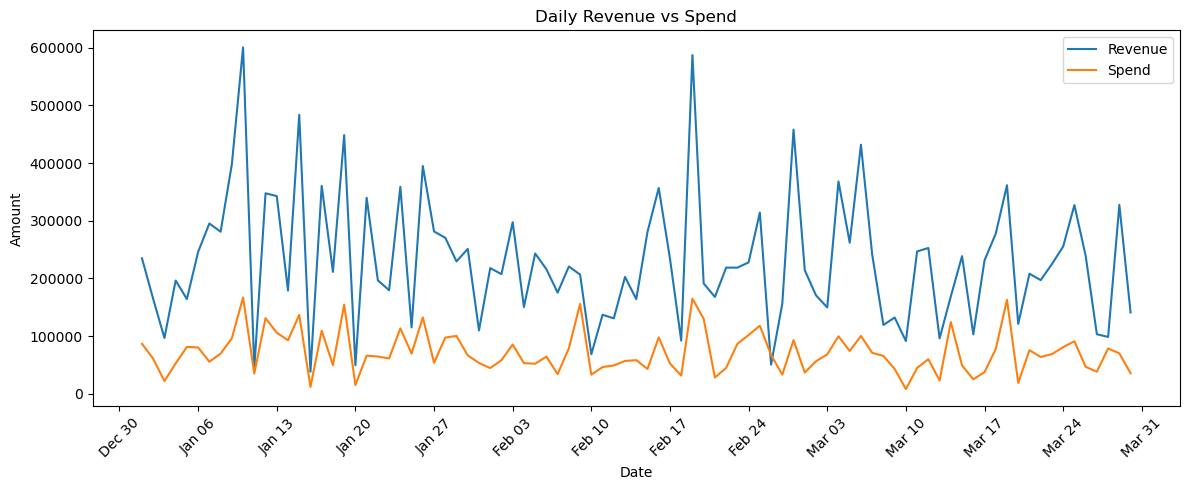

In [49]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(12, 5))

plt.plot(
    daily_trend['date'],
    daily_trend['revenue'],
    label='Revenue'
)

plt.plot(
    daily_trend['date'],
    daily_trend['spend'],
    label='Spend'
)

plt.title('Daily Revenue vs Spend')
plt.xlabel('Date')
plt.ylabel('Amount')
plt.legend()

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

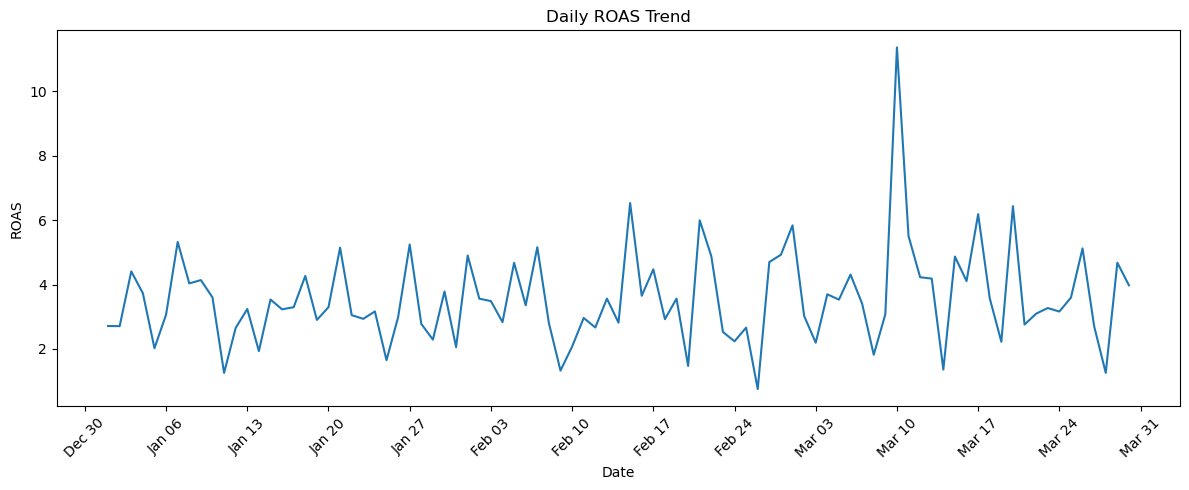

In [50]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_trend['date'],
    daily_trend['ROAS']
)

plt.title('Daily ROAS Trend')
plt.xlabel('Date')
plt.ylabel('ROAS')

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

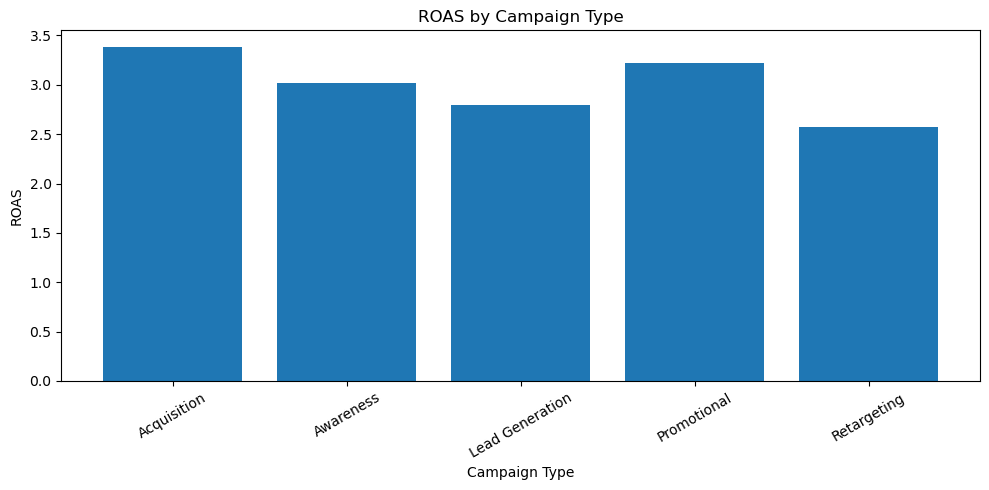

In [51]:
plt.figure(figsize=(10, 5))

plt.bar(
    campaign_type_analysis['campaign_type'],
    campaign_type_analysis['ROAS']
)

plt.title('ROAS by Campaign Type')
plt.xlabel('Campaign Type')
plt.ylabel('ROAS')

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

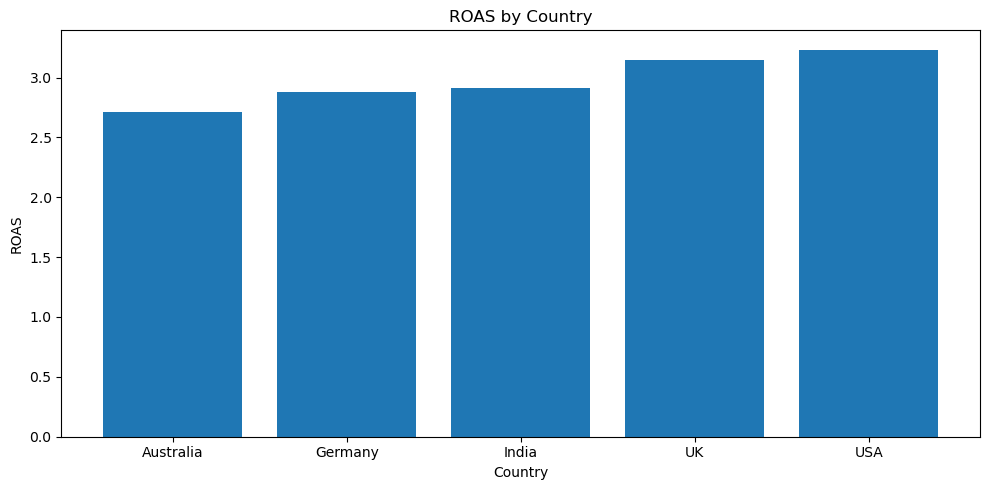

In [52]:
plt.figure(figsize=(10, 5))

plt.bar(
    country_analysis['country'],
    country_analysis['ROAS']
)

plt.title('ROAS by Country')
plt.xlabel('Country')
plt.ylabel('ROAS')

plt.tight_layout()
plt.show()

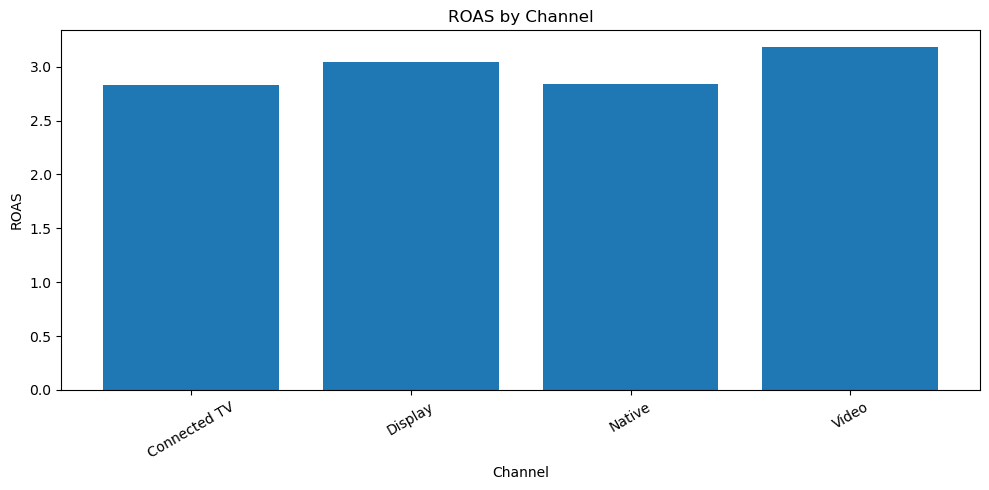

In [53]:
plt.figure(figsize=(10, 5))

plt.bar(
    channel_analysis['channel'],
    channel_analysis['ROAS']
)

plt.title('ROAS by Channel')
plt.xlabel('Channel')
plt.ylabel('ROAS')

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

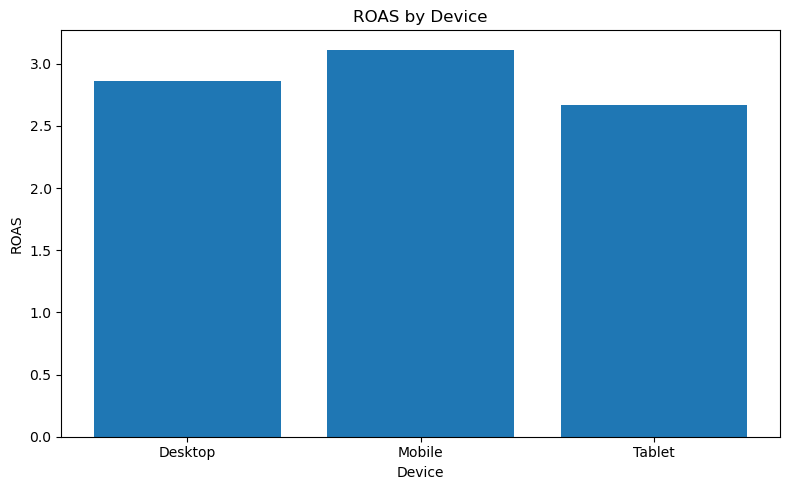

In [54]:
plt.figure(figsize=(8, 5))

plt.bar(
    device_analysis['device'],
    device_analysis['ROAS']
)

plt.title('ROAS by Device')
plt.xlabel('Device')
plt.ylabel('ROAS')

plt.tight_layout()
plt.show()

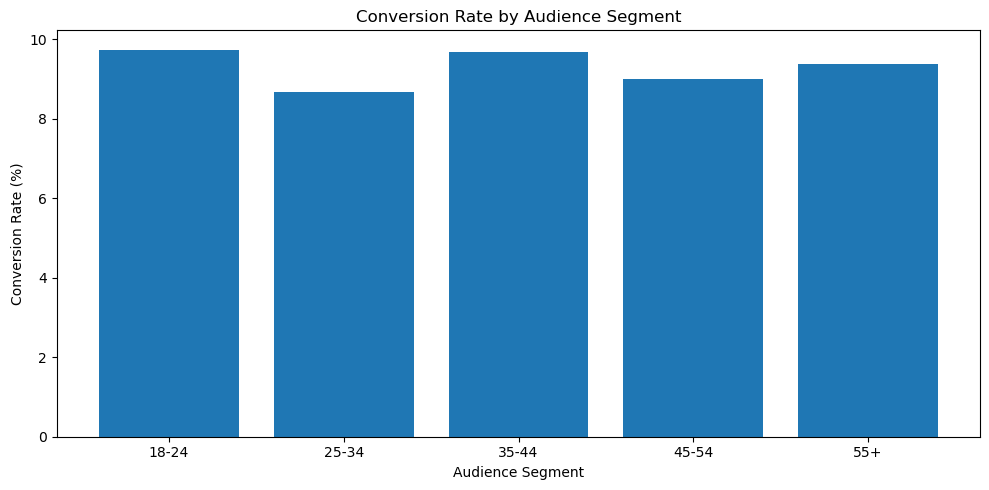

In [55]:
plt.figure(figsize=(10, 5))

plt.bar(
    audience_analysis['audience_segment'],
    audience_analysis['conversion_rate']
)

plt.title('Conversion Rate by Audience Segment')
plt.xlabel('Audience Segment')
plt.ylabel('Conversion Rate (%)')

plt.tight_layout()
plt.show()


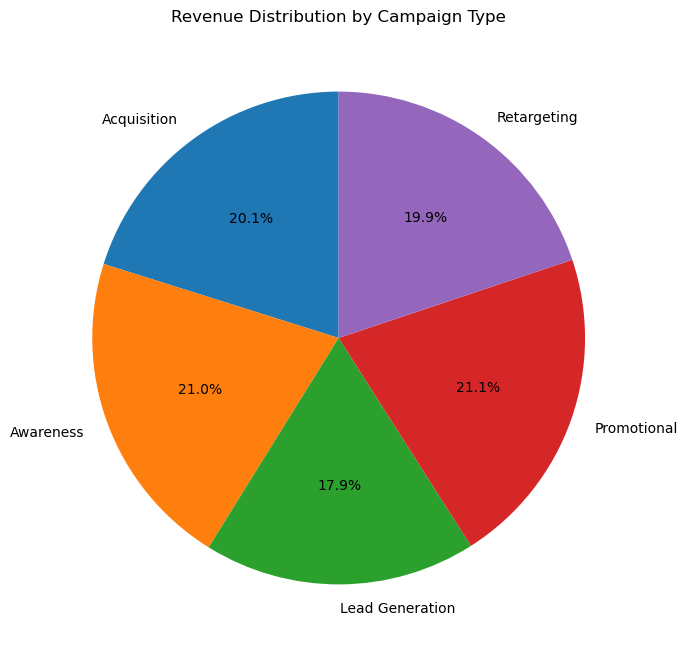

In [56]:
plt.figure(figsize=(8, 8))

plt.pie(
    campaign_type_analysis['revenue'],
    labels=campaign_type_analysis['campaign_type'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Distribution by Campaign Type')
plt.show()

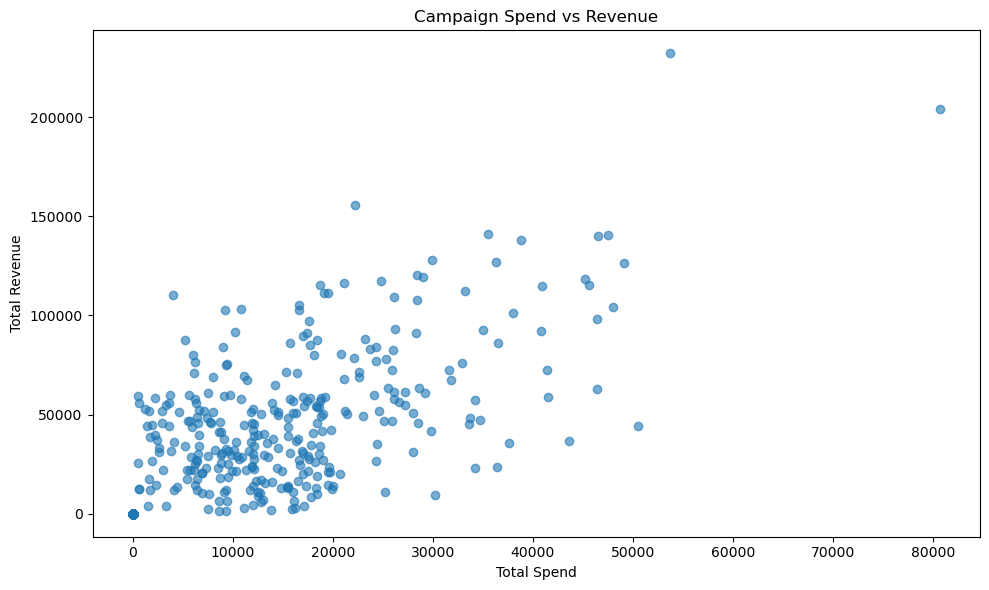

In [57]:
plt.figure(figsize=(10, 6))

plt.scatter(
    campaign_master['total_spend'],
    campaign_master['total_revenue'],
    alpha=0.6
)

plt.title('Campaign Spend vs Revenue')
plt.xlabel('Total Spend')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

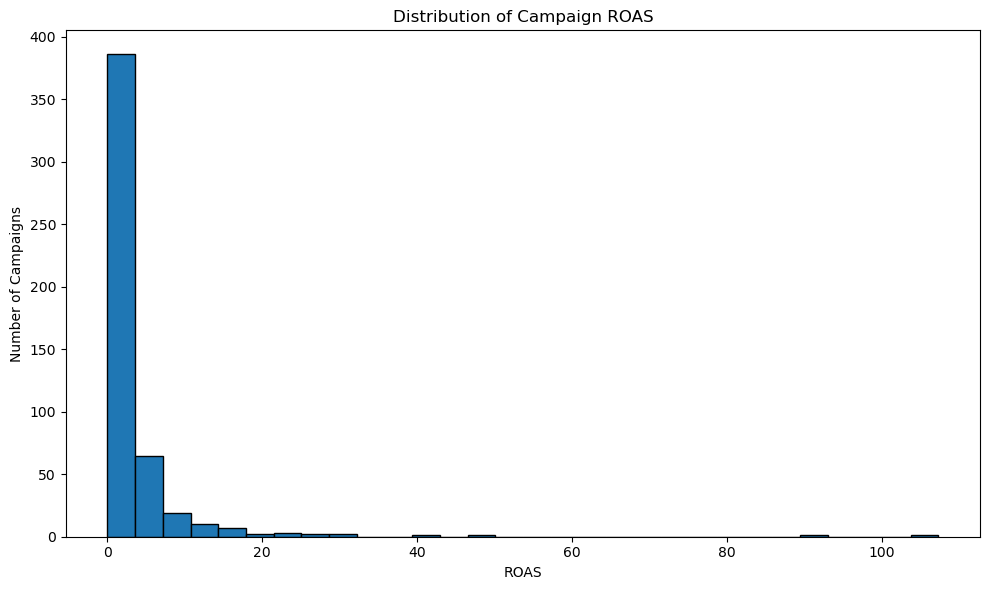

In [58]:
plt.figure(figsize=(10, 6))

plt.hist(
    campaign_master['ROAS'],
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Campaign ROAS')
plt.xlabel('ROAS')
plt.ylabel('Number of Campaigns')

plt.tight_layout()
plt.show()

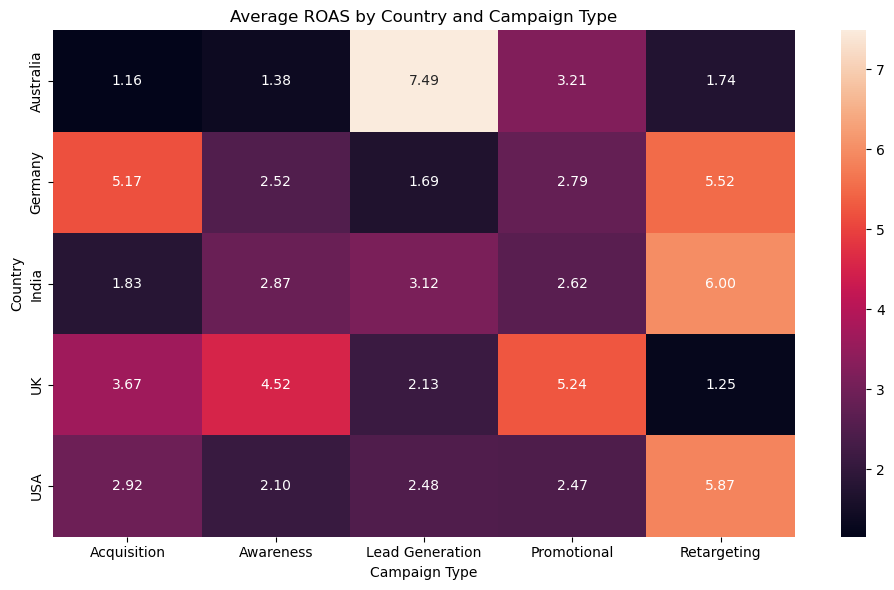

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

heatmap_data = campaign_master.pivot_table(
    index='country',
    columns='campaign_type',
    values='ROAS',
    aggfunc='mean'
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f'
)

plt.title('Average ROAS by Country and Campaign Type')
plt.xlabel('Campaign Type')
plt.ylabel('Country')

plt.tight_layout()
plt.show()


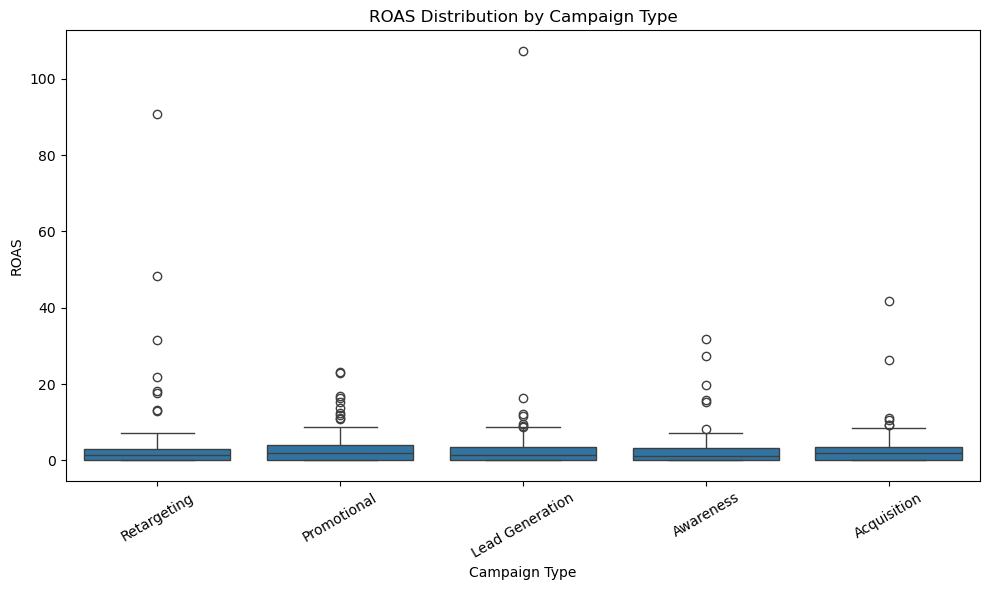

In [60]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=campaign_master,
    x='campaign_type',
    y='ROAS'
)

plt.title('ROAS Distribution by Campaign Type')
plt.xlabel('Campaign Type')
plt.ylabel('ROAS')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [62]:
campaign_master.to_csv("campaign_master.csv", index=False)

In [63]:
import os

print(os.getcwd())
print(os.path.exists("campaign_master.csv"))

C:\Users\Admin\data_analysis_project\data
True
